General Evaluation Function for Multiple Models & Datasets

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from tqdm import tqdm

In [29]:
def evaluate_models(models, model_names, data_loaders, dataset_names, device='cuda'):
    """
    General evaluation function for multiple models across multiple datasets.


    Args:
    models (list): list of PyTorch models.
    model_names (list): list of model names (strings).
    data_loaders (list): list of DataLoader objects for datasets.
    dataset_names (list): list of dataset names (strings).
    device (str): device to run evaluation ('cuda' or 'cpu').


    Returns:
    results_dict (dict): nested dictionary containing metrics for each model/dataset.
    """
    results_dict = {}


    for model, m_name in zip(models, model_names):
        model.to(device)
        model.eval()
        results_dict[m_name] = {}


        for loader, d_name in zip(data_loaders, dataset_names):
            y_true, y_pred, y_prob = [], [], []


            with torch.no_grad():
                for images, labels in tqdm(loader):
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                    probs = torch.softmax(outputs.logits, dim=1)[:, 1]
                    preds = torch.argmax(outputs.logits, dim=1)
                    y_true.extend(labels.cpu().numpy())
                    y_pred.extend(preds.cpu().numpy())
                    y_prob.extend(probs.cpu().numpy())


            # Compute metrics
            acc = accuracy_score(y_true, y_pred)
            prec = precision_score(y_true, y_pred)
            rec = recall_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            auc = roc_auc_score(y_true, y_prob)
            cm = confusion_matrix(y_true, y_pred)


            # Store results
            results_dict[m_name][d_name] = {
            'accuracy': acc,
            'precision': prec,
            'recall': rec,
            'f1': f1,
            'roc_auc': auc,
            'confusion_matrix': cm
            }


            # --- Plot confusion matrix ---
            plt.figure(figsize=(5,4))
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real','AI'], yticklabels=['Real','AI'])
            plt.title(f'Confusion Matrix: {m_name} on {d_name}')
            plt.xlabel('Predicted')
            plt.ylabel('True')
            plt.savefig(f"{m_name}_{d_name}", dpi=300)
            plt.show()


            # --- ROC Curve ---
            from sklearn.metrics import roc_curve
            fpr, tpr, _ = roc_curve(y_true, y_prob)
            plt.figure()
            plt.plot(fpr, tpr, label=f'{m_name} on {d_name} (AUC={auc:.2f})')
            plt.plot([0,1],[0,1],'--', color='gray')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title('ROC Curve')
            plt.legend()
            plt.show()


            # --- Classification report ---
            print(f'Classification Report for {m_name} on {d_name}:')
            print(classification_report(y_true, y_pred, target_names=['Real','AI']))


    return results_dict

In [3]:
class ImageCSVLoader(Dataset):
    def __init__(self, dataframe, processor):
        self.dataframe = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image = Image.open(row['path']).convert('RGB')
        label = int(row['label'])

        processed = self.processor(images=image, return_tensors="pt")
        pixel_values = processed['pixel_values'].squeeze(0)
        return pixel_values, label

In [4]:
df = pd.read_csv("../data/classifier_results.csv")

In [23]:
def map_to_coarse(category):
    if category in ["airplane", "automobile", "ship", "truck"]:
        return "object"
    else:
        return "animal"

In [24]:
coarse = []
for top_1 in df['top1_name']:
    coarse.append(map_to_coarse(top_1))

In [28]:
df['coarse'] = coarse

In [30]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

processor = AutoImageProcessor.from_pretrained("prithivMLmods/deepfake-detector-model-v1", use_fast=True)
model = AutoModelForImageClassification.from_pretrained("prithivMLmods/deepfake-detector-model-v1")
model.eval()

# create dataloaders for each category
groups = df.groupby('coarse')

dataloaders = []
names = []
for category, category_df in groups:
    dataset = ImageCSVLoader(category_df, processor)
    loader = DataLoader(dataset, batch_size=32, shuffle=False)
    dataloaders.append(loader)
    names.append(category)

100%|██████████| 2035/2035 [08:35<00:00,  3.95it/s]


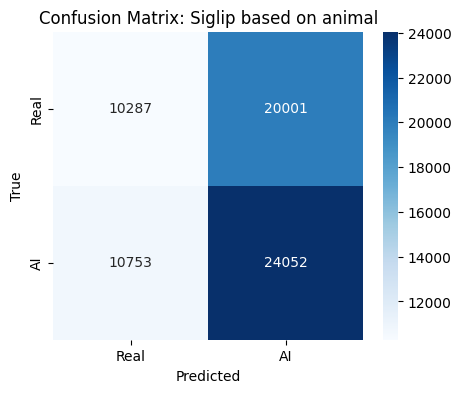

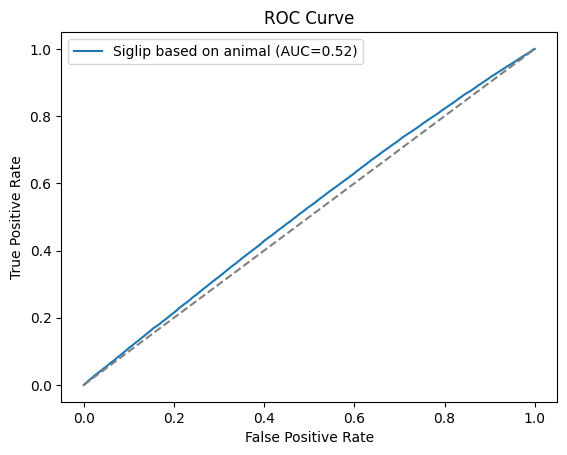

Classification Report for Siglip based on animal:
              precision    recall  f1-score   support

        Real       0.49      0.34      0.40     30288
          AI       0.55      0.69      0.61     34805

    accuracy                           0.53     65093
   macro avg       0.52      0.52      0.51     65093
weighted avg       0.52      0.53      0.51     65093



100%|██████████| 1404/1404 [05:23<00:00,  4.34it/s]


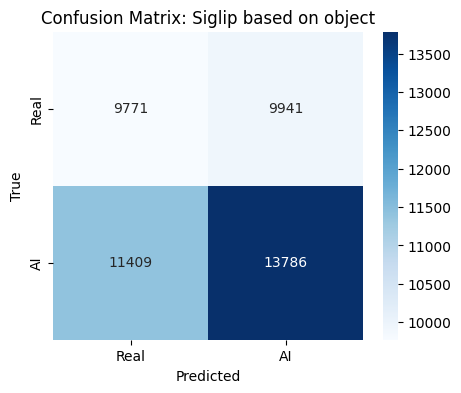

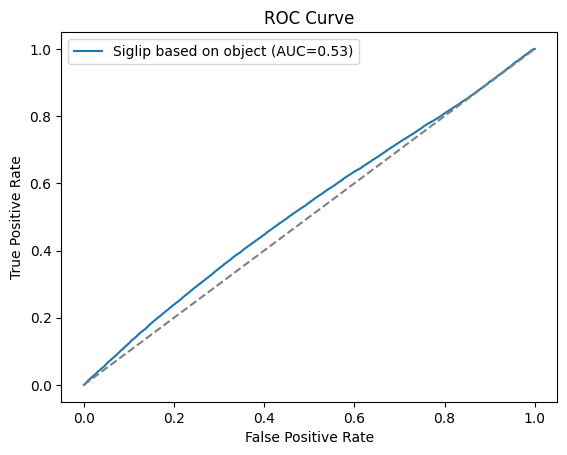

Classification Report for Siglip based on object:
              precision    recall  f1-score   support

        Real       0.46      0.50      0.48     19712
          AI       0.58      0.55      0.56     25195

    accuracy                           0.52     44907
   macro avg       0.52      0.52      0.52     44907
weighted avg       0.53      0.52      0.53     44907



In [31]:

models = [model]
model_names = ["Siglip based"]
results = evaluate_models(models, model_names, dataloaders, names)

In [32]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

processor = AutoImageProcessor.from_pretrained("prithivMLmods/Deep-Fake-Detector-v2-Model", use_fast=True)
model = AutoModelForImageClassification.from_pretrained("prithivMLmods/Deep-Fake-Detector-v2-Model")
model.eval()

# create dataloaders for each category
groups = df.groupby('coarse')

dataloaders = []
names = []
for category, category_df in groups:
    dataset = ImageCSVLoader(category_df, processor)
    loader = DataLoader(dataset, batch_size=32, shuffle=False)
    dataloaders.append(loader)
    names.append(category)

100%|██████████| 2035/2035 [07:23<00:00,  4.59it/s]


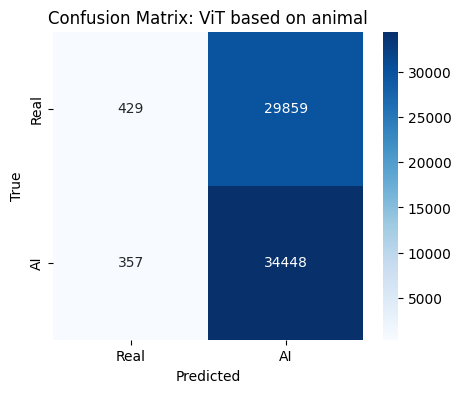

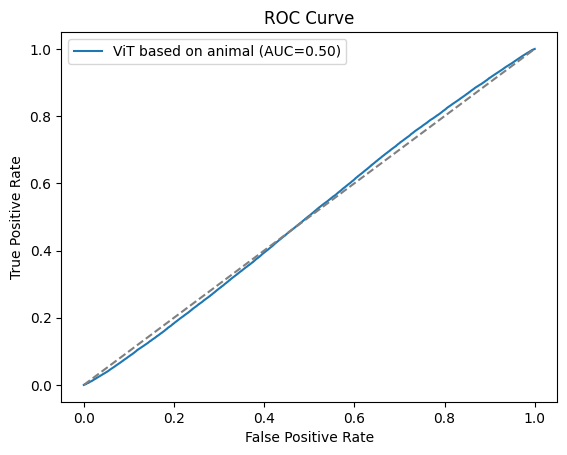

Classification Report for ViT based on animal:
              precision    recall  f1-score   support

        Real       0.55      0.01      0.03     30288
          AI       0.54      0.99      0.70     34805

    accuracy                           0.54     65093
   macro avg       0.54      0.50      0.36     65093
weighted avg       0.54      0.54      0.38     65093



100%|██████████| 1404/1404 [05:04<00:00,  4.61it/s]


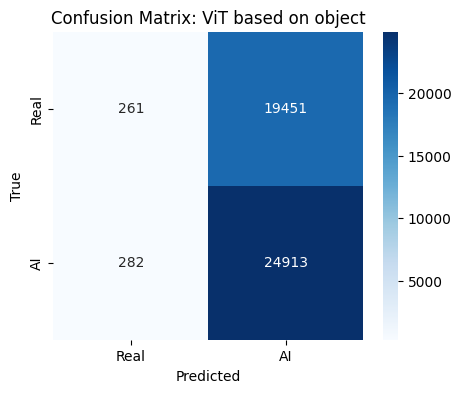

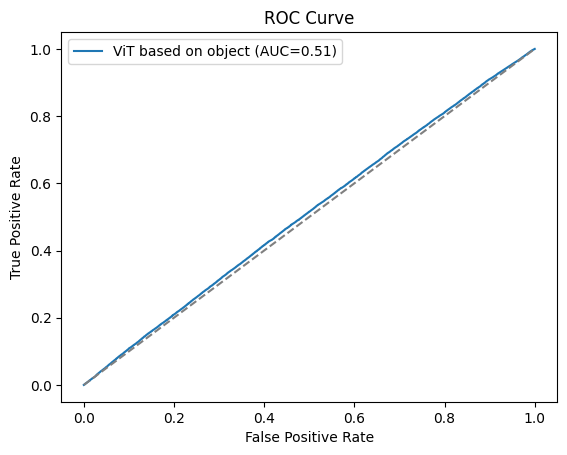

Classification Report for ViT based on object:
              precision    recall  f1-score   support

        Real       0.48      0.01      0.03     19712
          AI       0.56      0.99      0.72     25195

    accuracy                           0.56     44907
   macro avg       0.52      0.50      0.37     44907
weighted avg       0.53      0.56      0.41     44907



In [33]:

models = [model]
model_names = ["ViT based"]
results = evaluate_models(models, model_names, dataloaders, names)